# DEAP Dataset Inspection — `s01.dat`

This notebook inspects **one participant's** preprocessed DEAP data. It loads the two arrays, reviews channel and label metadata, checks quality, plots sample signals, and optionally extracts analysis-ready segments.

**Important:** `pickle` can execute code embedded in a file. **Only load `.dat` files from a source you trust** (such as your own official DEAP download). This notebook does not alter the source file.

Install if required: `pip install numpy pandas matplotlib`.

In [185]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Put s01.dat next to this notebook, or change this path.
FILE_PATH = Path("C:\\Users\\pipo\\Datasets-Docs\\DEAP_dataset\\deap-dataset\\data_preprocessed_python\\s02.dat")
FS = 128  # Hz, DEAP preprocessed release
BASELINE_SECONDS = 3
STIMULUS_SECONDS = 60
BASELINE_SAMPLES = FS * BASELINE_SECONDS

if not FILE_PATH.is_file():
    raise FileNotFoundError(f"File not found: {FILE_PATH.resolve()}")

# Only unpickle .dat files you trust.
with FILE_PATH.open("rb") as f:
    deap = pickle.load(f, encoding="latin1")

if not isinstance(deap, dict) or not {"data", "labels"}.issubset(deap):
    raise ValueError("Expected a dictionary containing 'data' and 'labels'.")

data = np.asarray(deap["data"])
labels = np.asarray(deap["labels"])
print("Keys:", list(deap))
print("Data:", data.shape, data.dtype)
print("Labels:", labels.shape, labels.dtype)
assert data.ndim == 3 and labels.ndim == 2
assert data.shape[0] == labels.shape[0], "Trial counts do not match"


Keys: ['labels', 'data']
Data: (40, 40, 8064) float64
Labels: (40, 4) float64


In [186]:

import numpy as np
import pandas as pd
import mne

# DEAP data
data = deap["data"]       # (40, 40, 8064)
labels = deap["labels"]   # (40, 4)

sfreq = 128

# 32 EEG channels in DEAP order
eeg_names = [
    "Fp1", "AF3", "F3", "F7", "FC5", "FC1", "C3", "T7",
    "CP5", "CP1", "P3", "P7", "PO3", "O1", "Oz", "Pz",
    "Fp2", "AF4", "Fz", "F4", "F8", "FC6", "FC2", "Cz",
    "C4", "T8", "CP6", "CP2", "P4", "P8", "PO4", "O2"
]

# 8 peripheral channels
peripheral_names = [
    "hEOG", "vEOG", "zEMG", "tEMG",
    "GSR", "Respiration", "Plethysmograph", "Temperature"
]

ch_names = eeg_names + peripheral_names

ch_types = (
    ["eeg"] * 32
    + ["eog"] * 2
    + ["emg"] * 2
    + ["misc"] * 4
)

# Convert EEG and EOG/EMG microvolts to volts
data_mne = data.copy()
data_mne[:, :36, :] *= 1e-6

# Create MNE information
info = mne.create_info(
    ch_names=ch_names,
    sfreq=sfreq,
    ch_types=ch_types
)

# Set electrode positions
montage = mne.channels.make_standard_montage("standard_1020")
info.set_montage(montage, on_missing="ignore")

# Metadata: emotion ratings per trial
metadata = pd.DataFrame(
    labels,
    columns=["Valence", "Arousal", "Dominance", "Liking"]
)
metadata.insert(0, "Trial", np.arange(1, len(labels) + 1))

# One event per trial, aligned with t=0 (stimulus start)
events = np.column_stack([
    np.arange(len(data_mne)) * data_mne.shape[-1] + 384,
    np.zeros(len(data_mne), dtype=int),
    np.ones(len(data_mne), dtype=int)
]).astype(int)

# Create MNE EpochsArray
epochs = mne.EpochsArray(
    data=data_mne,
    info=info,
    events=events,
    event_id={"Video": 1},
    tmin=-3.0,
    metadata=metadata,
    baseline=None,
    verbose=False
)

epochs


C:\Users\pipo\AppData\Local\Temp\ipykernel_9500\3551673120.py:46: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = mne.channels.make_standard_montage("standard_1020")


<EpochsArray | 40 events (all good), -3 – 59.992 s (baseline off), ~98.5 MiB, data loaded, with metadata,
 'Video': 40>

NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


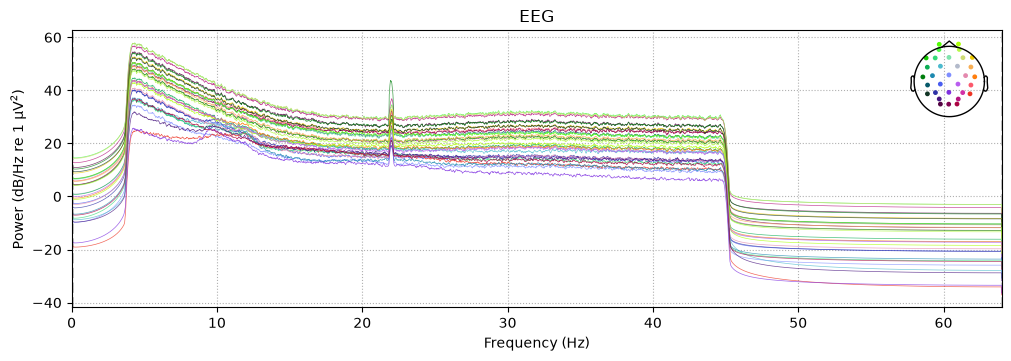

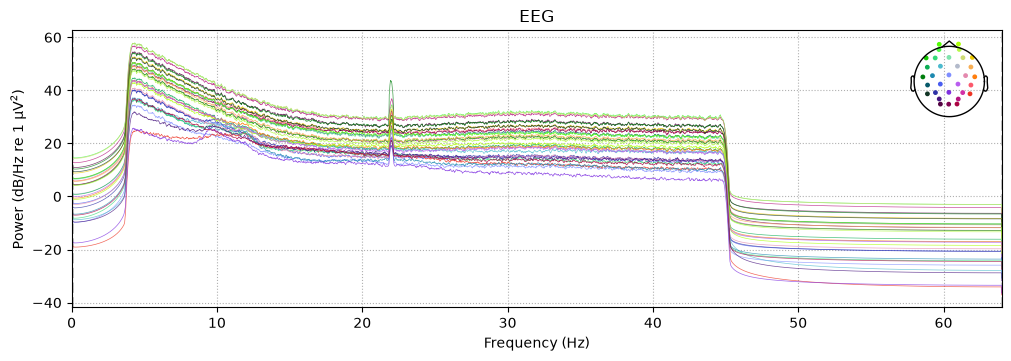

In [187]:
epochs.copy().pick('eeg').plot_psd()

In [188]:
epochs.copy().pick("emg").get_data()

array([[[ 9.27211828e-06,  1.09596152e-05,  7.42837169e-06, ...,
         -1.91602511e-04, -1.94290006e-04, -1.95321254e-04],
        [ 8.64174836e-07,  2.80167126e-06,  5.20425471e-07, ...,
          6.62390540e-05,  6.68328029e-05,  6.57390550e-05]],

       [[ 2.65294920e-05,  3.22169815e-05,  3.91857186e-05, ...,
         -9.71890294e-05, -1.05189015e-04, -1.03907767e-04],
        [ 1.46563857e-05,  8.78139653e-06,  1.19063908e-05, ...,
          1.98062297e-04,  1.91093560e-04,  1.93874805e-04]],

       [[ 1.87633931e-05,  1.35134028e-05,  1.37321524e-05, ...,
         -5.42052221e-05, -5.59864688e-05, -5.95489622e-05],
        [ 1.16610299e-05,  1.21922789e-05,  1.36610262e-05, ...,
          1.96723188e-04,  1.97129437e-04,  1.96316939e-04]],

       ...,

       [[ 7.38133402e-06,  1.31000735e-05,  9.28758049e-06, ...,
          7.37874613e-05,  7.68187057e-05,  7.53812084e-05],
        [ 1.24694594e-04,  1.32382080e-04,  1.25819592e-04, ...,
          2.36663137e-04,  2.33225

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


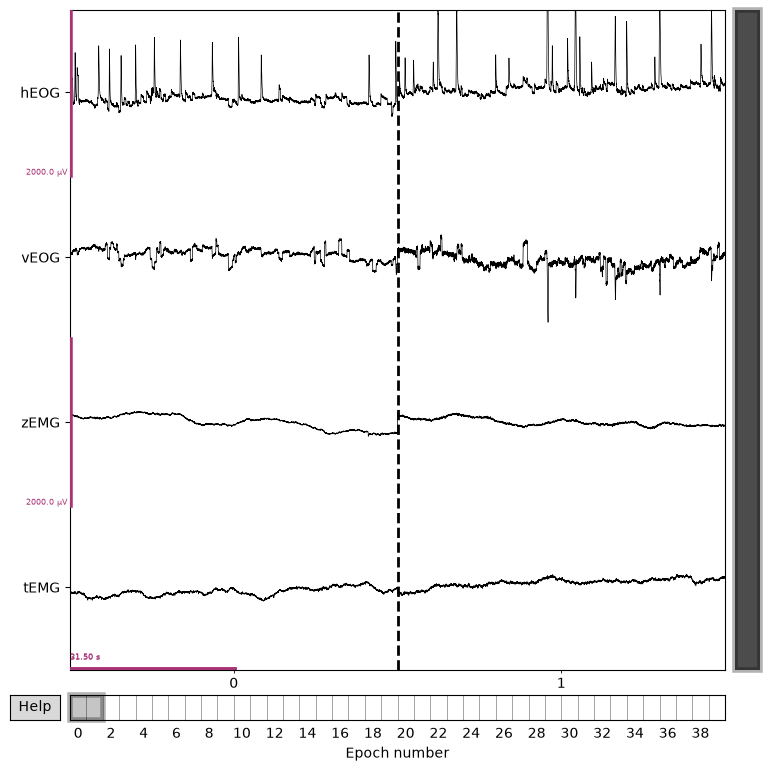

..
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


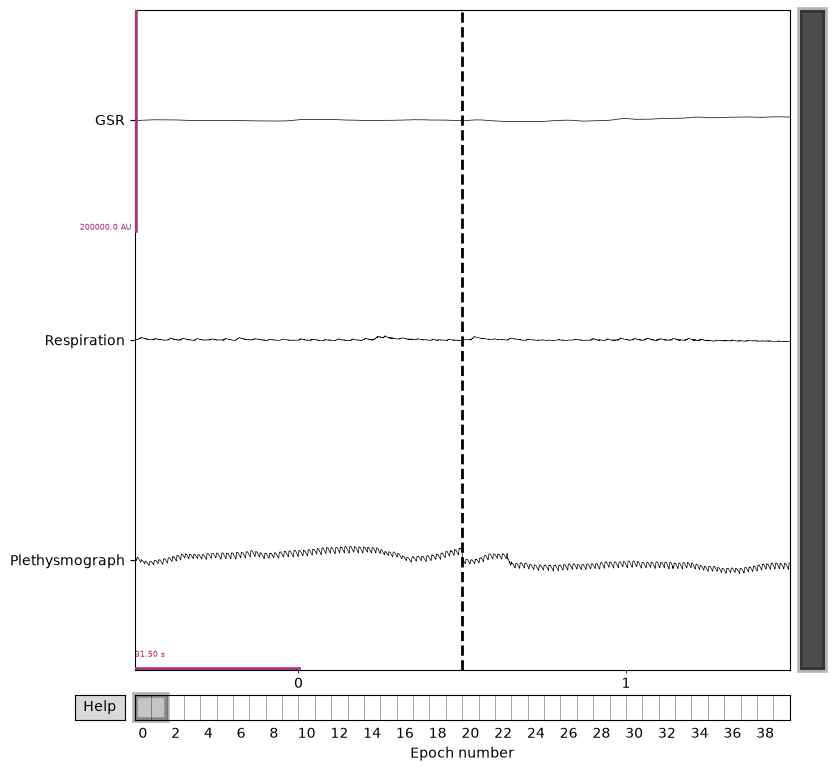

..


In [189]:
epochs.copy().pick(["hEOG", "vEOG", "zEMG", "tEMG"]).plot(picks="all",
    n_epochs=2,
    scalings="1e-3")

print("..")

epochs.copy().pick(["GSR", "Respiration", "Plethysmograph"]).plot(picks="all",
    n_epochs=2,
    scalings="1e5")

print("..")

In [190]:
labels

array([[0.  , 3.97, 7.13, 6.62],
       [0.99, 1.9 , 8.04, 8.08],
       [0.  , 0.  , 8.96, 8.05],
       [6.05, 1.  , 5.04, 7.03],
       [5.04, 3.  , 3.65, 5.04],
       [5.  , 4.94, 5.04, 1.01],
       [4.96, 1.99, 4.08, 1.  ],
       [0.  , 0.  , 9.  , 9.  ],
       [0.  , 2.  , 9.  , 7.18],
       [4.99, 1.  , 9.  , 1.  ],
       [7.08, 1.  , 7.01, 7.  ],
       [0.99, 2.94, 7.12, 9.  ],
       [9.  , 4.99, 9.  , 9.  ],
       [0.06, 0.  , 8.97, 9.  ],
       [0.  , 0.99, 8.06, 9.  ],
       [3.  , 3.95, 8.05, 6.14],
       [9.  , 3.  , 6.03, 7.41],
       [0.  , 2.85, 9.  , 8.08],
       [0.  , 0.68, 8.06, 6.99],
       [0.03, 0.  , 8.03, 9.  ],
       [1.  , 1.  , 5.04, 1.  ],
       [5.  , 1.  , 4.97, 5.  ],
       [1.  , 2.97, 1.  , 7.82],
       [1.92, 0.  , 6.06, 9.  ],
       [0.  , 0.  , 8.1 , 9.  ],
       [0.  , 0.96, 9.  , 9.  ],
       [4.96, 5.01, 3.01, 5.05],
       [4.06, 4.97, 7.14, 7.04],
       [2.99, 7.04, 7.03, 9.  ],
       [2.01, 7.05, 1.  , 7.13],
       [4.

## 3. Emotion-rating labels

Each row holds ratings **[valence, arousal, dominance, liking]** for a complete trial. These are **trial-level subjective ratings**, not continuous annotations at each time point. The expected DEAP rating range is **1–9**.

This particular uploaded `s01.dat` has out-of-range valence values. They are flagged below; the notebook deliberately **does not correct or clip** them because their cause has not been verified.

In [191]:
LABEL_NAMES = ["Valence", "Arousal", "Dominance", "Liking"]
if labels.shape[1] != 4:
    raise ValueError("Expected 4 label columns for standard DEAP data.")
labels_df = pd.DataFrame(labels, columns=LABEL_NAMES)
labels_df.index = np.arange(1, len(labels_df) + 1)
labels_df.index.name = "Trial (1-based)"
print("First 10 trials:")
display(labels_df.head(10))
print("Summary statistics:")
display(labels_df.describe().T)


First 10 trials:


,Valence,Arousal,Dominance,Liking
Trial (1-based),,,,
1,0.00,3.97,7.13,6.62
2,0.99,1.90,8.04,8.08
3,0.00,0.00,8.96,8.05
4,6.05,1.00,5.04,7.03
5,5.04,3.00,3.65,5.04
6,5.00,4.94,5.04,1.01
7,4.96,1.99,4.08,1.00
8,0.00,0.00,9.00,9.00
9,0.00,2.00,9.00,7.18


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Valence,40.0,2.67600,2.607555,0.0,0.0525,1.955,4.9675,9.0
Arousal,40.0,2.96675,2.744529,0.0,1.0000,2.000,4.9475,9.0
Dominance,40.0,5.84075,2.823592,1.0,3.4900,7.000,8.0600,9.0
Liking,40.0,5.68000,3.294365,1.0,1.0000,7.015,9.0000,9.0


In [192]:
# Values outside the expected [1, 9] scale
out_of_range = (labels_df < 1) | (labels_df > 9)
flagged = (
    labels_df.stack().rename("value").reset_index()
    .rename(columns={"level_1": "Emotion dimension"})
)
flagged = flagged[(flagged["value"] < 1) | (flagged["value"] > 9)]
print("Out-of-range rating count:", len(flagged))
display(flagged if not flagged.empty else pd.DataFrame({"Status": ["No out-of-range ratings"]}))

# Check data integrity
print("All signal values finite:", bool(np.isfinite(data).all()))
print("All rating values finite:", bool(np.isfinite(labels).all()))
# Peak-to-peak over trials and samples, per channel
constant_channels = np.flatnonzero(np.ptp(data, axis=(0, 2)) == 0)
print("Constant channel indices (0-based):", constant_channels.tolist())


Out-of-range rating count: 22


,Trial (1-based),Emotion dimension,value
0,1,Valence,0.00
4,2,Valence,0.99
8,3,Valence,0.00
9,3,Arousal,0.00
28,8,Valence,0.00
29,8,Arousal,0.00
32,9,Valence,0.00
44,12,Valence,0.99
52,14,Valence,0.06
53,14,Arousal,0.00


All signal values finite: True
All rating values finite: True
Constant channel indices (0-based): []


## 7. Visualize emotion ratings

Note that the scatter plot uses **original recorded values**, including out-of-range values. Inspect label provenance before performing a classification or regression experiment.

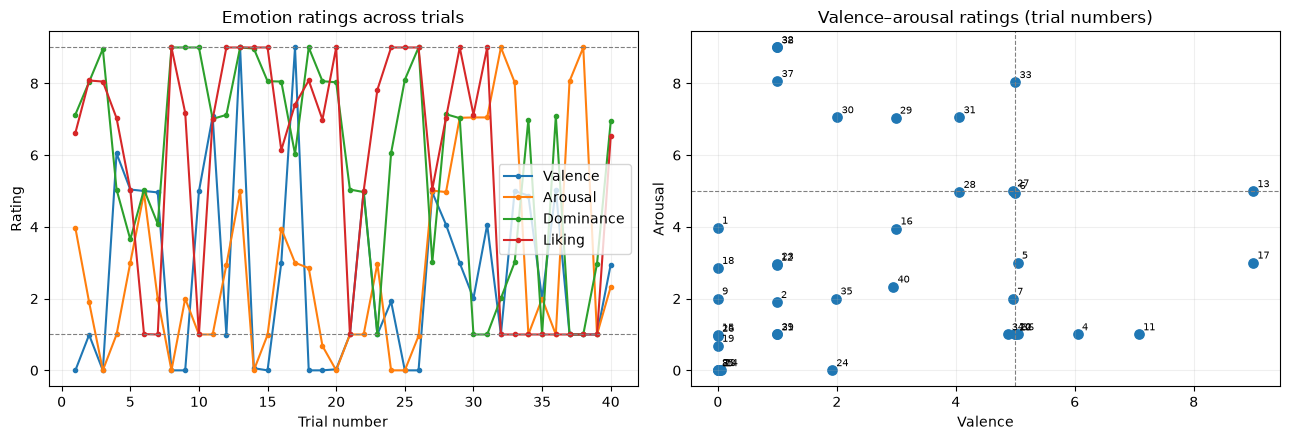

In [193]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name in LABEL_NAMES:
    axes[0].plot(labels_df.index, labels_df[name], marker="o", ms=3, label=name)
axes[0].axhline(1, ls="--", lw=0.8, color="gray")
axes[0].axhline(9, ls="--", lw=0.8, color="gray")
axes[0].set(xlabel="Trial number", ylabel="Rating", title="Emotion ratings across trials")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].scatter(labels_df["Valence"], labels_df["Arousal"], s=45)
for i, (x, y) in enumerate(zip(labels_df["Valence"], labels_df["Arousal"]), start=1):
    axes[1].annotate(str(i), (x, y), xytext=(3, 3), textcoords="offset points", fontsize=7)
axes[1].axvline(5, ls="--", color="gray", lw=0.8)
axes[1].axhline(5, ls="--", color="gray", lw=0.8)
axes[1].set(xlabel="Valence", ylabel="Arousal", title="Valence–arousal ratings (trial numbers)")
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()


## Notes and references

- This is the **preprocessed Python** DEAP release, not the raw BDF recordings.
- DEAP: Koelstra et al., *DEAP: A Database for Emotion Analysis Using Physiological Signals*, IEEE Transactions on Affective Computing (2012). https://www.eecs.qmul.ac.uk/mmv/datasets/deap/
- DEAP documentation describes the preprocessed subject-file shapes and channel information: https://www.eecs.qmul.ac.uk/mmv/datasets/deap/readme.html
- The unexpected ratings in the supplied file are reported as found, without automatically inferring or applying any correction.
- For cross-subject experiments, load all participants and perform subject-level data splitting to avoid leakage.
